# Indian Railways next-stop delay benchmark

This experiment compares 13 requested supervised algorithms and retains Histogram Gradient Boosting, the previous benchmark's test MAE leader. Each row represents the segment from a reported departure to the next station. All learned methods use the same chronological partitions and feature preparation.

- **Regression:** Estimate the change from current departure delay to next-stop arrival delay. Add the departure delay to the predicted change and score the resulting forecast in minutes.
- **Classification:** Predict whether the next arrival is **more than five minutes late**. This is an experimental threshold. A delay of exactly five minutes belongs to the other class.
- **Persistence:** Carry the current departure delay forward. For classification, apply the same threshold to that carried-forward value.

## Run locally on Windows

For a new or recreated project environment, install the benchmark dependencies and register its Jupyter kernel in PowerShell.

```powershell
Set-Location C:\GANGBANG
.\env\python.exe -m pip install -r requirements-benchmark.txt
.\env\python.exe -m ipykernel install --user --name raahai-benchmark --display-name "RaahAI Benchmark (Python 3.10)"
```

Open this notebook from the repository in VS Code. Choose **RaahAI Benchmark (Python 3.10)** in the kernel picker and select **Run All**. The first cell reports the interpreter and package versions. Training may take several minutes.

In [1]:
from pathlib import Path
import sys
from time import perf_counter

import catboost
import lightgbm as lgb
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow
import sklearn
import xgboost as xgb
from IPython import get_ipython
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (
    AdaBoostRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor,
    RandomForestRegressor,
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score, f1_score,
    mean_absolute_error, median_absolute_error, precision_recall_curve,
    precision_score, r2_score, recall_score, roc_auc_score, root_mean_squared_error,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.svm import SVC, SVR
from sklearn.tree import DecisionTreeRegressor
from threadpoolctl import threadpool_limits

get_ipython().run_line_magic("matplotlib", "inline")

SEED = 42
FILE_FRACTION = 0.01
N_JOBS = 4
ROW_CAPS = {"Train": 24_000, "Validation": 16_000, "Test": 16_000}
LATE_THRESHOLD = 5
WINDOWS = {
    "Train": ("2026-01-01", "2026-07-01"),
    "Validation": ("2026-07-01", "2026-08-01"),
    "Test": ("2026-08-01", "2026-09-01"),
}

feature_suffix = Path("processed/features/year=2026")
feature_dir = next(
    (folder / feature_suffix for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / feature_suffix / "_data_dictionary.csv").is_file()),
    None,
)
if feature_dir is None:
    raise FileNotFoundError(
        f"Could not find {feature_suffix / '_data_dictionary.csv'} from {Path.cwd()}. "
        "Open the project folder in VS Code and run the notebook from that folder."
    )

display(pd.Series({
    "Python": sys.version.split()[0],
    "Kernel executable": sys.executable,
    "NumPy": np.__version__,
    "pandas": pd.__version__,
    "PyArrow": pyarrow.__version__,
    "scikit-learn": sklearn.__version__,
    "LightGBM": lgb.__version__,
    "XGBoost": xgb.__version__,
    "CatBoost": catboost.__version__,
    "Matplotlib": matplotlib.__version__,
}, name="Version").to_frame())

,Version
Python,3.10.22
Kernel executable,c:\GANGBANG\env\python.exe
NumPy,2.2.6
pandas,2.3.3
PyArrow,25.0.1
scikit-learn,1.7.2
LightGBM,4.7.0
XGBoost,3.2.0
CatBoost,1.2.10
Matplotlib,3.10.9


## Sample and chronological split

The sample is drawn without replacement from sorted parquet paths with a fixed seed. The file percentage refers to partitions, which vary in size. Each split has a row cap so the benchmark can run on a laptop. The counts below distinguish sampled rows from rows actually used.

The benchmark uses segments with a recorded departure delay and a directly observed arrival delay. It excludes imputed arrival labels and segments flagged for implausible speed. The chronological split uses the journey start date, with a cutoff on the realized arrival timestamp so an outcome that occurs after the end of a split cannot contribute to that split. July is used for validation and ranking. August is reserved for evaluation.

Features come from the repository data dictionary. The input includes timetable, network, historical, and selected live fields available at departure. Outcome columns, raw IDs, timestamps, and month or day-of-year are excluded from the model inputs.

The shared training cap is 24,000 rows to make exact RBF-kernel SVM and SVR practical on a local machine. The same seeded partition draw, eligibility rules and 16,000-row validation and test caps from the earlier benchmark are used. The changed training size can affect comparisons with numbers from the earlier notebook run.

In [2]:
TARGET = "y_arr_delay_B"
CURRENT = "known_delay_A"
CATEGORICAL = ["train_type"]
DEPARTURE_FEATURES = {
    CURRENT, "arr_delay_A", "dwell_overrun_A", "gain_prev1", "gain_prev2",
    "trend_2stops", "max_dep_delay_so_far",
}
EXCLUDED = {
    "date", "train_no", "from_stn", "to_stn", "from_seq", "to_seq",
    "sch_dep_A", "sch_arr_B", "month", "day_of_year",
}

dictionary = pd.read_csv(feature_dir / "_data_dictionary.csv")
available_by_departure = (
    dictionary["known_when"].isin(["schedule", "history"])
    | dictionary["column"].isin(DEPARTURE_FEATURES)
)
feature_cols = dictionary.loc[
    available_by_departure & ~dictionary["column"].isin(EXCLUDED), "column"
].tolist()
numeric_cols = [name for name in feature_cols if name not in CATEGORICAL]
assert CURRENT in feature_cols and TARGET not in feature_cols

paths = sorted(path for path in feature_dir.rglob("*.parquet") if not path.name.startswith("_"))
if not paths:
    raise FileNotFoundError(f"No feature parquet files found under {feature_dir}")
sample_count = max(1, round(len(paths) * FILE_FRACTION))
indices = sorted(np.random.default_rng(SEED).choice(len(paths), sample_count, replace=False))
chosen_paths = [paths[index] for index in indices]

read_cols = feature_cols + [
    "date", "sch_arr_B", TARGET, "known_delay_A_src", "arr_imputed_B", "flag_speed"
]
data = pd.concat(
    (pd.read_parquet(path, columns=read_cols) for path in chosen_paths),
    ignore_index=True,
)
data["date"] = pd.to_datetime(data["date"])
data["observed_arrival"] = (
    pd.to_datetime(data["sch_arr_B"]) + pd.to_timedelta(data[TARGET], unit="min")
)
eligible = (
    data["known_delay_A_src"].eq("dep")
    & np.isfinite(data[CURRENT])
    & np.isfinite(data[TARGET])
    & ~data["arr_imputed_B"].fillna(True)
    & ~data["flag_speed"].fillna(True)
)

splits = {}
counts = []
for split, (start, stop) in WINDOWS.items():
    within_dates = data["date"].ge(start) & data["date"].lt(stop)
    within_cutoff = data["observed_arrival"].lt(stop)
    candidates = data.loc[within_dates & within_cutoff & eligible]
    if candidates.empty:
        raise ValueError(f"No eligible {split.lower()} rows. Increase FILE_FRACTION.")
    chosen = candidates.sample(n=min(len(candidates), ROW_CAPS[split]), random_state=SEED)
    splits[split] = chosen.sort_values("date").copy()
    counts.append({
        "Split": split,
        "From": start,
        "Until (exclusive)": stop,
        "Sampled rows by journey date": int(within_dates.sum()),
        "Eligible rows": len(candidates),
        "Rows used": len(chosen),
    })

assert splits["Train"]["observed_arrival"].max() < pd.Timestamp(WINDOWS["Validation"][0])
assert splits["Validation"]["observed_arrival"].max() < pd.Timestamp(WINDOWS["Test"][0])
print(f"Sampled {sample_count:,} of {len(paths):,} parquet files ({sample_count / len(paths):.2%}).")
print(f"Read {len(data):,} segment rows. Selected {len(feature_cols)} input features.")
display(pd.DataFrame(counts).set_index("Split"))

Sampled 128 of 12,758 parquet files (1.00%).
Read 289,185 segment rows. Selected 57 input features.


,From,Until (exclusive),Sampled rows by journey date,Eligible rows,Rows used
Split,,,,,
Train,2026-01-01,2026-07-01,212697,172303,24000
Validation,2026-07-01,2026-08-01,37708,30602,16000
Test,2026-08-01,2026-09-01,38780,31353,16000


## Feature preprocessing and comparison protocol

Training data determines the median imputation values and category encoding. Scale-sensitive estimators also fit a standard scaler on their training inputs. Hyperparameters and the late-arrival threshold are fixed before reviewing the validation and test results. Each table orders learned models by July performance, using MAE for regression and positive-class F1 for classification. August provides the held-out evaluation.

The regression comparison includes Linear Regression, Decision Tree, Random Forest, SVR, KNN, Gradient Boosting, XGBoost, LightGBM, CatBoost and AdaBoost. Histogram Gradient Boosting is included as a comparator from the earlier benchmark. The classification comparison uses Logistic Regression, SVM (RBF SVC) and Gaussian Naive Bayes.

In [3]:
def input_frame(frame):
    inputs = frame[feature_cols].copy()
    inputs[numeric_cols] = (
        inputs[numeric_cols].replace([np.inf, -np.inf], np.nan).astype(np.float32)
    )
    inputs["train_type"] = inputs["train_type"].astype("string").fillna("<missing>").astype(str)
    return inputs


preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True), numeric_cols),
    ("category", OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float32), CATEGORICAL),
])
frames = {name: input_frame(frame) for name, frame in splits.items()}
start = perf_counter()
encoded_train = preprocessor.fit_transform(frames["Train"])
encoded_names = preprocessor.get_feature_names_out()
encoded_names = [str(name).replace(" ", "_") for name in encoded_names]
X = {"Train": pd.DataFrame(encoded_train, columns=encoded_names)}
for split in ("Validation", "Test"):
    X[split] = pd.DataFrame(preprocessor.transform(frames[split]), columns=encoded_names)

observed = {name: frame[TARGET].to_numpy(dtype=float) for name, frame in splits.items()}
current = {name: frame[CURRENT].to_numpy(dtype=float) for name, frame in splits.items()}
train_delta = observed["Train"] - current["Train"]
print(f"Encoded {X['Train'].shape[1]} features in {perf_counter() - start:.2f} seconds.")

Encoded 85 features in 0.16 seconds.


## Regression models

The models estimate the change in delay. Ordinary least squares uses double precision to reduce numerical sensitivity to redundant feature columns. MAE, RMSE and median absolute error evaluate the resulting arrival delay in minutes. Bias is prediction minus observation. The within-five and within-fifteen metrics count errors within the corresponding tolerance, including its endpoints.

In [4]:
regressors = {
    "Linear Regression": make_pipeline(
        FunctionTransformer(np.asarray, kw_args={"dtype": np.float64}),
        StandardScaler(),
        LinearRegression(),
    ),
    "Decision Tree": DecisionTreeRegressor(max_depth=12, min_samples_leaf=20, random_state=SEED),
    "Random Forest": RandomForestRegressor(
        n_estimators=60, max_depth=15, min_samples_leaf=15, max_features=0.55,
        n_jobs=N_JOBS, random_state=SEED,
    ),
    "SVR (RBF)": make_pipeline(StandardScaler(), SVR(C=8.0, epsilon=1.5, cache_size=256)),
    "KNN": make_pipeline(
        StandardScaler(), KNeighborsRegressor(n_neighbors=25, weights="distance", n_jobs=N_JOBS),
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        loss="absolute_error", n_estimators=100, learning_rate=0.08, max_depth=4,
        min_samples_leaf=20, random_state=SEED,
    ),
    "XGBoost": xgb.XGBRegressor(
        objective="reg:absoluteerror", n_estimators=180, learning_rate=0.06,
        max_depth=6, min_child_weight=15, reg_lambda=1.0, tree_method="hist",
        n_jobs=N_JOBS, random_state=SEED,
    ),
    "LightGBM": lgb.LGBMRegressor(
        objective="regression_l1", n_estimators=180, learning_rate=0.06,
        num_leaves=31, min_child_samples=30, reg_lambda=1.0, n_jobs=N_JOBS,
        random_state=SEED, deterministic=True, force_col_wise=True, verbosity=-1,
    ),
    "CatBoost": catboost.CatBoostRegressor(
        loss_function="MAE", iterations=240, depth=6, learning_rate=0.08,
        thread_count=N_JOBS, random_seed=SEED, verbose=False, allow_writing_files=False,
    ),
    "AdaBoost": AdaBoostRegressor(
        estimator=DecisionTreeRegressor(max_depth=4, min_samples_leaf=12, random_state=SEED),
        n_estimators=90, learning_rate=0.5, random_state=SEED,
    ),
    "Histogram Gradient Boosting": HistGradientBoostingRegressor(
        loss="absolute_error", max_iter=160, learning_rate=0.08, max_leaf_nodes=31,
        min_samples_leaf=30, early_stopping=False, random_state=SEED,
    ),
}


def regression_scores(actual, forecast):
    error = forecast - actual
    absolute = np.abs(error)
    return {
        "MAE (min)": mean_absolute_error(actual, forecast),
        "RMSE (min)": root_mean_squared_error(actual, forecast),
        "Median AE (min)": median_absolute_error(actual, forecast),
        "Bias (min)": error.mean(),
        "R²": r2_score(actual, forecast),
        "Within 5 min (%)": 100 * np.mean(absolute <= 5),
        "Within 15 min (%)": 100 * np.mean(absolute <= 15),
    }


evaluated_splits = ("Validation", "Test")
baseline = "Persistence (baseline)"
regression_rows = {split: {} for split in evaluated_splits}
for split in evaluated_splits:
    regression_rows[split][baseline] = {**regression_scores(observed[split], current[split]), "Fit (s)": np.nan}

with threadpool_limits(limits=N_JOBS):
    for name, model in regressors.items():
        start = perf_counter()
        model.fit(X["Train"], train_delta)
        fit_seconds = perf_counter() - start
        for split in evaluated_splits:
            forecast = current[split] + model.predict(X[split])
            regression_rows[split][name] = {**regression_scores(observed[split], forecast), "Fit (s)": fit_seconds}
        print(f"{name}: fit in {fit_seconds:.2f} s", flush=True)

regression_results = {
    split: pd.DataFrame.from_dict(rows, orient="index").rename_axis("Algorithm")
    for split, rows in regression_rows.items()
}

Linear Regression: fit in 0.09 s
Decision Tree: fit in 0.70 s
Random Forest: fit in 5.36 s
SVR (RBF): fit in 15.63 s
KNN: fit in 0.03 s
Gradient Boosting: fit in 28.03 s
XGBoost: fit in 1.93 s
LightGBM: fit in 0.56 s
CatBoost: fit in 2.37 s
AdaBoost: fit in 13.44 s
Histogram Gradient Boosting: fit in 1.51 s


### Regression comparison tables

The same order is used in both tables so the July validation ranking can be traced into August. The persistence row is displayed last.

In [5]:
def order_by_validation(results, column, ascending):
    order = results["Validation"].drop(index=baseline).sort_values(column, ascending=ascending).index
    return [*order, baseline]


regression_order = order_by_validation(regression_results, "MAE (min)", ascending=True)
for split in evaluated_splits:
    print(f"{split} regression results")
    display(regression_results[split].loc[regression_order].round(3))
print("Lowest held-out regression MAE:",
      regression_results["Test"].drop(index=baseline)["MAE (min)"].idxmin())

Validation regression results


,MAE (min),RMSE (min),Median AE (min),Bias (min),R²,Within 5 min (%),Within 15 min (%),Fit (s)
Algorithm,,,,,,,,
XGBoost,2.495,6.059,1.000,-0.587,0.992,88.794,97.356,1.933
Histogram Gradient Boosting,2.498,6.081,1.004,-0.639,0.992,88.975,97.325,1.514
LightGBM,2.498,6.081,1.000,-0.626,0.992,88.875,97.288,0.558
CatBoost,2.509,6.096,0.997,-0.671,0.992,88.969,97.269,2.374
Gradient Boosting,2.518,6.101,1.007,-0.586,0.992,88.706,97.288,28.026
Random Forest,2.588,5.805,1.132,0.079,0.993,88.488,97.488,5.357
SVR (RBF),2.642,6.391,1.112,-0.368,0.991,88.700,97.138,15.632
Linear Regression,2.726,5.969,1.233,0.042,0.992,87.525,97.288,0.092
Decision Tree,2.869,6.299,1.126,0.068,0.991,86.075,96.756,0.699


Test regression results


,MAE (min),RMSE (min),Median AE (min),Bias (min),R²,Within 5 min (%),Within 15 min (%),Fit (s)
Algorithm,,,,,,,,
XGBoost,2.377,5.533,0.990,-0.551,0.992,89.275,97.625,1.933
Histogram Gradient Boosting,2.375,5.545,0.991,-0.590,0.992,89.312,97.644,1.514
LightGBM,2.371,5.536,0.988,-0.583,0.992,89.288,97.569,0.558
CatBoost,2.388,5.550,0.979,-0.622,0.992,89.262,97.569,2.374
Gradient Boosting,2.391,5.532,0.996,-0.538,0.992,89.231,97.631,28.026
Random Forest,2.477,5.325,1.114,0.093,0.992,88.406,97.800,5.357
SVR (RBF),2.528,5.823,1.093,-0.329,0.991,89.094,97.394,15.632
Linear Regression,2.590,5.437,1.204,0.066,0.992,88.081,97.581,0.092
Decision Tree,2.775,5.887,1.126,0.124,0.990,86.025,97.019,0.699


Lowest held-out regression MAE: LightGBM


## Late-arrival classifiers

The positive class marks arrivals more than five minutes late. Positive-class F1 balances precision and recall. Balanced accuracy gives equal weight to the two classes. ROC AUC and average precision use the model's continuous score, with the carried-forward delay acting as the persistence score. SVC uses its decision function, while Logistic Regression and Gaussian Naive Bayes use positive-class probabilities. The tables also display accuracy and fit time.

In [6]:
late = {split: (delay > LATE_THRESHOLD).astype(int) for split, delay in observed.items()}
display(pd.DataFrame({
    "Rows": {split: len(values) for split, values in late.items()},
    "Arrivals > 5 min late (%)": {split: 100 * values.mean() for split, values in late.items()},
}).rename_axis("Split").round(3))

classifiers = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=1000)),
    "SVM (RBF SVC)": make_pipeline(StandardScaler(), SVC(C=4.0, cache_size=256)),
    "Gaussian Naive Bayes": make_pipeline(StandardScaler(), GaussianNB()),
}


def classification_scores(actual, prediction, score):
    return {
        "Accuracy (%)": 100 * accuracy_score(actual, prediction),
        "Balanced accuracy (%)": 100 * balanced_accuracy_score(actual, prediction),
        "Precision (%)": 100 * precision_score(actual, prediction, zero_division=0),
        "Recall (%)": 100 * recall_score(actual, prediction, zero_division=0),
        "F1 (%)": 100 * f1_score(actual, prediction, zero_division=0),
        "ROC AUC": roc_auc_score(actual, score),
        "Average precision": average_precision_score(actual, score),
    }


classification_rows = {split: {} for split in evaluated_splits}
test_scores = {baseline: current["Test"]}
for split in evaluated_splits:
    prediction = current[split] > LATE_THRESHOLD
    classification_rows[split][baseline] = {
        **classification_scores(late[split], prediction, current[split]), "Fit (s)": np.nan,
    }

with threadpool_limits(limits=N_JOBS):
    for name, model in classifiers.items():
        start = perf_counter()
        model.fit(X["Train"], late["Train"])
        fit_seconds = perf_counter() - start
        for split in evaluated_splits:
            prediction = model.predict(X[split])
            score = (
                model.decision_function(X[split]) if hasattr(model, "decision_function")
                else model.predict_proba(X[split])[:, 1]
            )
            classification_rows[split][name] = {
                **classification_scores(late[split], prediction, score), "Fit (s)": fit_seconds,
            }
            if split == "Test":
                test_scores[name] = score
        print(f"{name}: fit in {fit_seconds:.2f} s", flush=True)

classification_results = {
    split: pd.DataFrame.from_dict(rows, orient="index").rename_axis("Algorithm")
    for split, rows in classification_rows.items()
}

,Rows,Arrivals > 5 min late (%)
Split,,
Train,24000,76.808
Validation,16000,77.869
Test,16000,77.600


Logistic Regression: fit in 0.26 s
SVM (RBF SVC): fit in 19.28 s
Gaussian Naive Bayes: fit in 0.04 s


### Classification comparison tables

The models are ordered by July validation F1. August shows how each fixed model performed on later data. Compare both F1 and average precision with persistence.

In [7]:
classification_order = order_by_validation(classification_results, "F1 (%)", ascending=False)
for split in evaluated_splits:
    print(f"{split} classification results")
    display(classification_results[split].loc[classification_order].round(3))
print("Highest held-out classification F1:",
      classification_results["Test"].drop(index=baseline)["F1 (%)"].idxmax())

Validation classification results


,Accuracy (%),Balanced accuracy (%),Precision (%),Recall (%),F1 (%),ROC AUC,Average precision,Fit (s)
Algorithm,,,,,,,,
Logistic Regression,95.219,93.241,97.062,96.789,96.926,0.981,0.995,0.258
SVM (RBF SVC),92.606,89.693,95.556,94.919,95.237,0.974,0.993,19.277
Gaussian Naive Bayes,78.375,71.924,88.109,83.498,85.741,0.826,0.944,0.038
Persistence (baseline),90.256,82.828,91.730,96.155,93.891,0.925,0.973,NaN


Test classification results


,Accuracy (%),Balanced accuracy (%),Precision (%),Recall (%),F1 (%),ROC AUC,Average precision,Fit (s)
Algorithm,,,,,,,,
Logistic Regression,94.975,93.031,96.959,96.553,96.755,0.980,0.994,0.258
SVM (RBF SVC),92.281,89.410,95.403,94.612,95.006,0.972,0.992,19.277
Gaussian Naive Bayes,77.388,71.834,88.126,81.894,84.896,0.817,0.939,0.038
Persistence (baseline),90.200,82.769,91.570,96.231,93.842,0.927,0.973,NaN


Highest held-out classification F1: Logistic Regression


## Comparison graphs

The regression charts compare August MAE and RMSE. The classification charts compare August F1 and precision–recall behaviour. The dashed horizontal reference in the precision–recall panel shows the positive-class prevalence.

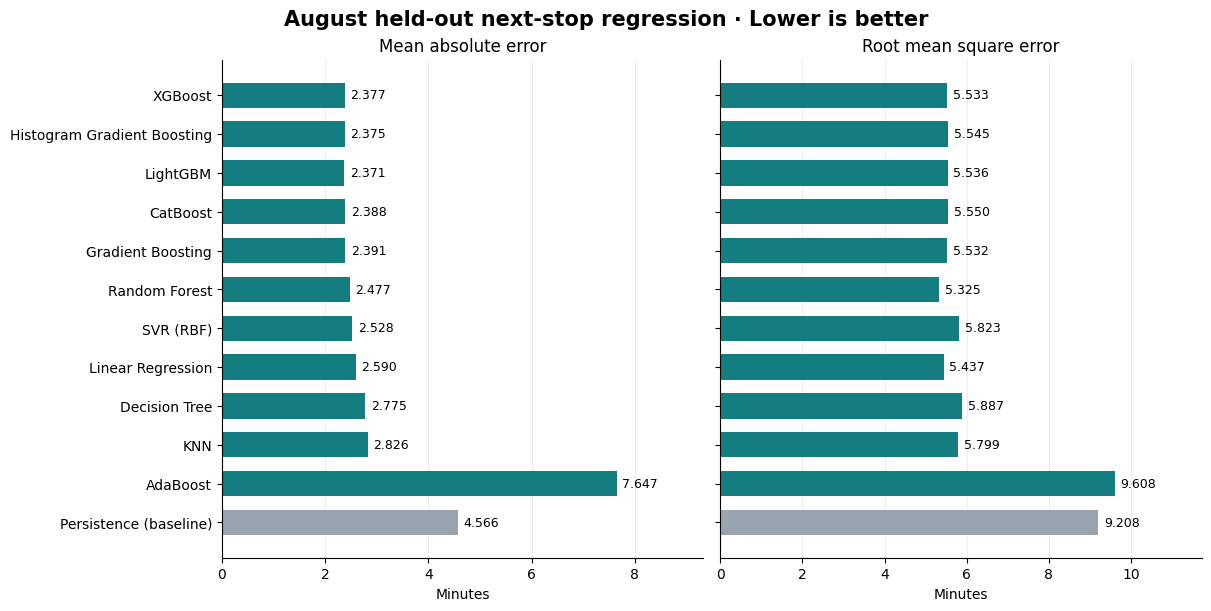

In [8]:
def horizontal_bars(axis, values, title, label, decimals=2):
    colors = ["#9aa4ae" if name == baseline else "#147d80" for name in values.index]
    bars = axis.barh(values.index, values, color=colors, height=0.65)
    axis.bar_label(bars, fmt=f"%.{decimals}f", padding=4, fontsize=9)
    axis.set_xlim(0, values.max() * 1.22)
    axis.set(title=title, xlabel=label)
    axis.grid(axis="x", alpha=0.22)
    axis.set_axisbelow(True)
    axis.spines[["top", "right"]].set_visible(False)


regression_figure, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True, layout="constrained")
test_regression = regression_results["Test"].loc[regression_order]
horizontal_bars(axes[0], test_regression["MAE (min)"], "Mean absolute error", "Minutes", decimals=3)
horizontal_bars(axes[1], test_regression["RMSE (min)"], "Root mean square error", "Minutes", decimals=3)
axes[0].invert_yaxis()
axes[1].tick_params(labelleft=False)
regression_figure.suptitle("August held-out next-stop regression · Lower is better", fontsize=15, fontweight="bold")
plt.show()

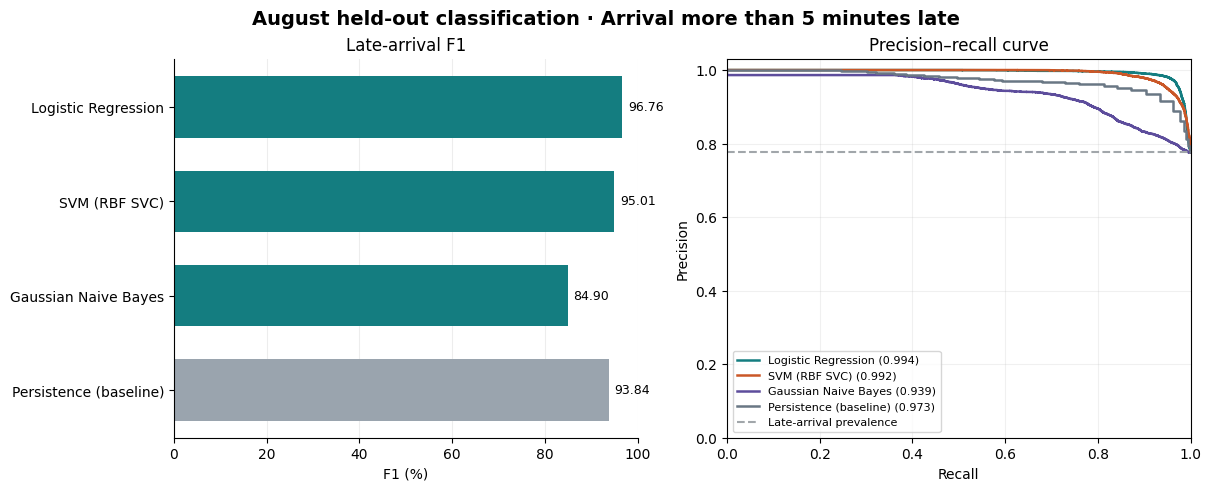

In [9]:
classification_figure, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
test_classification = classification_results["Test"].loc[classification_order]
horizontal_bars(axes[0], test_classification["F1 (%)"], "Late-arrival F1", "F1 (%)")
axes[0].set_xlim(0, 100)
axes[0].invert_yaxis()
for name, color in zip(classification_order, ["#147d80", "#ca5727", "#5d4d9c", "#697784"]):
    precision, recall, _ = precision_recall_curve(late["Test"], test_scores[name])
    average_precision = test_classification.at[name, "Average precision"]
    axes[1].step(recall, precision, where="post", label=f"{name} ({average_precision:.3f})",
                 color=color, linewidth=1.8)
axes[1].axhline(late["Test"].mean(), color="#a1a6aa", linestyle="--", label="Late-arrival prevalence")
axes[1].set(title="Precision–recall curve", xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1.03))
axes[1].grid(alpha=0.18)
axes[1].legend(loc="lower left", fontsize=8)
classification_figure.suptitle("August held-out classification · Arrival more than 5 minutes late",
                               fontsize=14, fontweight="bold")
plt.show()

## Interpretation

Regression measures the accuracy of a forecast in minutes. Classification measures identification of arrivals more than five minutes late. These are separate outcomes, and MAE and F1 do not share a ranking. Small differences on this sampled next-stop experiment should be checked on additional journeys before choosing a different model. A deployment decision for the route finder also requires multi-stop accuracy and interval calibration. The benchmark fits its models in memory and supplies comparison evidence for the separately trained forecasting application.